<a href="https://colab.research.google.com/github/dsaik3395-crypto/SCT_WD_2/blob/main/ML_CASE_STUDY.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Machine Learning for Diabetes Prediction: A Comparative Analysis of Classification Models**




**Guide: Dr.Rambabu Pemula**

**Authors: M.Ajithosh(24911A6699), D.Sai kumar(24911A6678),  Aldrin Paul (24911A66A6)**

# **Problem Statement**
The problem is to predict the onset or presence of diabetes in patients using diagnostic medical measurements. This is formulated as a binary classification problem where the target variable is "Outcome" (0 indicating no diabetes, and 1 indicating diabetes).

# **Objective**
The primary objective of this case study is to preprocess the medical data—specifically handling zero-values in columns like Glucose and BloodPressure by replacing them with median values, and scaling the features. Furthermore, the objective is to build, train, test, and evaluate three distinct machine learning classifiers: K-Nearest Neighbors (KNN), Support Vector Machine (SVM), and a Decision Tree. The final goal is to compare these algorithms to determine the best model for predicting diabetes based on accuracy.

# **Data Collection**   
*   The data is based on the standard diabetes.csv file (commonly known as the Pima Indians Diabetes Database)
*   You can download the CSV file directly from https://github.com/plotly/datasets/blob/master/diabetes.csv
*    The dataset contains exactly 768 patient records with 9 distinct columns.   The collected features include Pregnancies, Glucose, BloodPressure, SkinThickness, Insulin, BMI, DiabetesPedigreeFunction, Age, and the target column Outcome.





#**Import the Required Libraries**




In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

#**Connect Google Drive and Read the Dataset**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/diabetes.csv')

print("Dataset Shape:", df.shape)
print(df.head())

Dataset Shape: (768, 9)
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  


# **Understand the Dataset**

In [ ]:
print(df.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB
None


In [ ]:

print(df.describe())


       Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count   768.000000  768.000000     768.000000     768.000000  768.000000   
mean      3.845052  120.894531      69.105469      20.536458   79.799479   
std       3.369578   31.972618      19.355807      15.952218  115.244002   
min       0.000000    0.000000       0.000000       0.000000    0.000000   
25%       1.000000   99.000000      62.000000       0.000000    0.000000   
50%       3.000000  117.000000      72.000000      23.000000   30.500000   
75%       6.000000  140.250000      80.000000      32.000000  127.250000   
max      17.000000  199.000000     122.000000      99.000000  846.000000   

              BMI  DiabetesPedigreeFunction         Age     Outcome  
count  768.000000                768.000000  768.000000  768.000000  
mean    31.992578                  0.471876   33.240885    0.348958  
std      7.884160                  0.331329   11.760232    0.476951  
min      0.000000                  

In [ ]:

print(df.isnull().sum())

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


Outcome
0    500
1    268
Name: count, dtype: int64


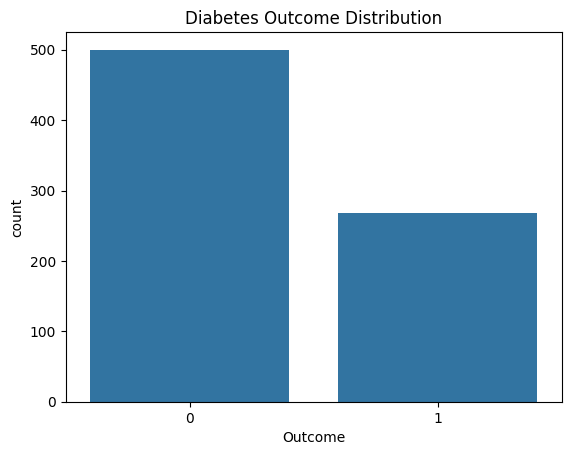

In [ ]:
print(df['Outcome'].value_counts())

sns.countplot(data=df, x='Outcome')
plt.title("Diabetes Outcome Distribution")
plt.show()

# **Data Preprocessing**

In [ ]:
df_clean = df.copy()

zero_columns = [
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI'
]

df_clean[zero_columns] = df_clean[zero_columns].replace(0, np.nan)

print(df_clean.isnull().sum())

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [ ]:
X = df_clean.drop('Outcome', axis=1)
y = df_clean['Outcome']

print("Features:", X.shape)
print("Target:", y.shape)

Features: (768, 8)
Target: (768,)


# **Split the Dataset Into Training and Testing**

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (537, 8)
X_test: (231, 8)
y_train: (537,)
y_test: (231,)


# **Handle Missing Values and Scale the Features**

In [ ]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy='median')

X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Preprocessing completed successfully")

Preprocessing completed successfully


# **Build, Train and Test the Models**
---
# **Model 1: K-Nearest Neighbors (KNN)**


**Build the Model**

In [ ]:
knn = KNeighborsClassifier(n_neighbors=5)
knn

KNeighborsClassifier()

**Train the Model**

In [ ]:
knn.fit(X_train, y_train)

KNeighborsClassifier()

**Test the Model**

In [ ]:
y_pred_knn = knn.predict(X_test)

print("Predicted Values:")
print(y_pred_knn[:10])

print("Actual Values:")
print(y_test.values[:10])

Predicted Values:
[0 0 1 1 0 0 1 0 0 0]
Actual Values:
[1 1 1 1 1 0 0 0 0 0]


**Display Correct and Wrong Predictions**

In [ ]:
print("Actual\tPredicted\tResult")

for actual, predicted in zip(y_test, y_pred_knn):
    result = "Correct" if actual == predicted else "Wrong"
    print(f"{actual}\t{predicted}\t\t{result}")

Actual	Predicted	Result
1	0		Wrong
1	0		Wrong
1	1		Correct
1	1		Correct
1	0		Wrong
0	0		Correct
0	1		Wrong
0	0		Correct
0	0		Correct
0	0		Correct
0	0		Correct
0	0		Correct
0	0		Correct
0	1		Wrong
1	1		Correct
1	1		Correct
1	1		Correct
0	0		Correct
0	1		Wrong
0	0		Correct
0	0		Correct
0	0		Correct
0	0		Correct
0	0		Correct
0	1		Wrong
0	0		Correct
1	0		Wrong
1	0		Wrong
0	0		Correct
0	0		Correct
1	1		Correct
1	0		Wrong
0	0		Correct
0	0		Correct
0	0		Correct
1	1		Correct
0	0		Correct
1	0		Wrong
0	0		Correct
0	0		Correct
0	0		Correct
1	1		Correct
0	0		Correct
0	0		Correct
0	0		Correct
1	1		Correct
0	0		Correct
1	1		Correct
0	0		Correct
0	0		Correct
0	0		Correct
0	0		Correct
1	1		Correct
0	0		Correct
1	1		Correct
1	0		Wrong
0	0		Correct
1	0		Wrong
1	1		Correct
1	0		Wrong
0	0		Correct
0	0		Correct
1	0		Wrong
1	0		Wrong
0	0		Correct
0	0		Correct
0	0		Correct
0	0		Correct
0	0		Correct
0	0		Correct
1	1		Correct
1	1		Correct
0	0		Correct
0	0		Correct
0	0		Correct
1	1		Correct
1	1		Correct
0	0		Co

**Evaluate KNN Performance**

In [ ]:
print("KNN Accuracy:", accuracy_score(y_test, y_pred_knn))
print("KNN Precision:", precision_score(y_test, y_pred_knn))
print("KNN Recall:", recall_score(y_test, y_pred_knn))
print("KNN F1-Score:", f1_score(y_test, y_pred_knn))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_knn))

KNN Accuracy: 0.7445887445887446
KNN Precision: 0.6527777777777778
KNN Recall: 0.5802469135802469
KNN F1-Score: 0.6143790849673203

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.83      0.81       150
           1       0.65      0.58      0.61        81

    accuracy                           0.74       231
   macro avg       0.72      0.71      0.71       231
weighted avg       0.74      0.74      0.74       231


Confusion Matrix:
[[125  25]
 [ 34  47]]


**Visualize the Confusion Matrix**

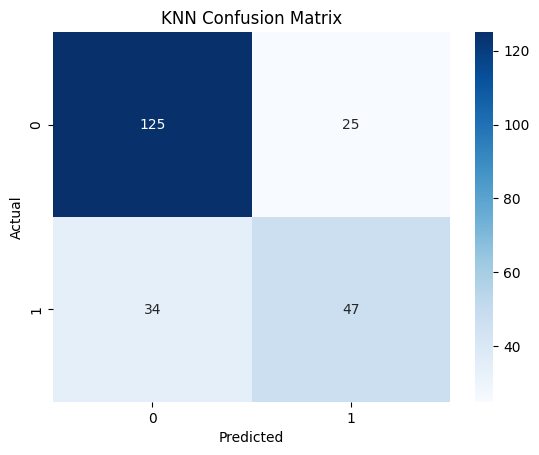

In [ ]:
sns.heatmap(
    confusion_matrix(y_test, y_pred_knn),
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# **Model 2: Support Vector Machine (SVM)**



**Build the Model**

In [ ]:
svm = SVC(kernel='rbf', random_state=42)

**Train the Model**

In [ ]:
svm.fit(X_train, y_train)

SVC(random_state=42)

**Test the Model**

In [ ]:
y_pred_svm = svm.predict(X_test)

print(y_pred_svm[:10])

[0 0 1 1 1 0 1 0 0 0]


**Evaluate SVM Performance**

SVM Accuracy: 0.7445887445887446
SVM Precision: 0.6833333333333333
SVM Recall: 0.5061728395061729
SVM F1-Score: 0.5815602836879432

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.87      0.82       150
           1       0.68      0.51      0.58        81

    accuracy                           0.74       231
   macro avg       0.72      0.69      0.70       231
weighted avg       0.74      0.74      0.73       231



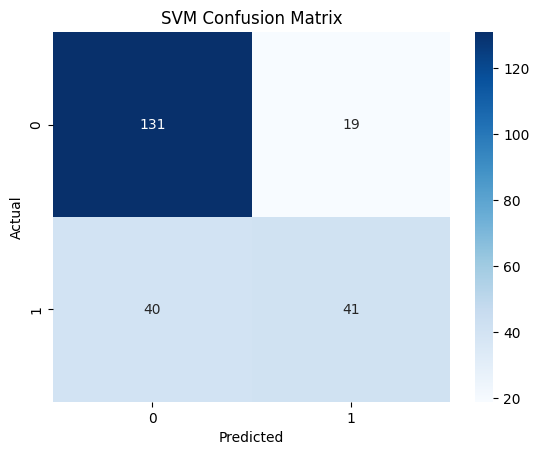

In [ ]:
print("SVM Accuracy:", accuracy_score(y_test, y_pred_svm))
print("SVM Precision:", precision_score(y_test, y_pred_svm))
print("SVM Recall:", recall_score(y_test, y_pred_svm))
print("SVM F1-Score:", f1_score(y_test, y_pred_svm))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm))

sns.heatmap(
    confusion_matrix(y_test, y_pred_svm),
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# **Model 3: Decision Tree**

**Build the Model**

In [ ]:
dt = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

**Train the Model**

In [ ]:
dt.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=4, random_state=42)

**Test the Model**

In [ ]:
y_pred_dt = dt.predict(X_test)

print(y_pred_dt[:10])

[0 0 1 1 0 0 1 0 0 0]


**Evaluate Decision Tree Performance**

Decision Tree Accuracy: 0.70995670995671
Decision Tree Precision: 0.64
Decision Tree Recall: 0.3950617283950617
Decision Tree F1-Score: 0.48854961832061067

Classification Report:
              precision    recall  f1-score   support

           0       0.73      0.88      0.80       150
           1       0.64      0.40      0.49        81

    accuracy                           0.71       231
   macro avg       0.68      0.64      0.64       231
weighted avg       0.70      0.71      0.69       231



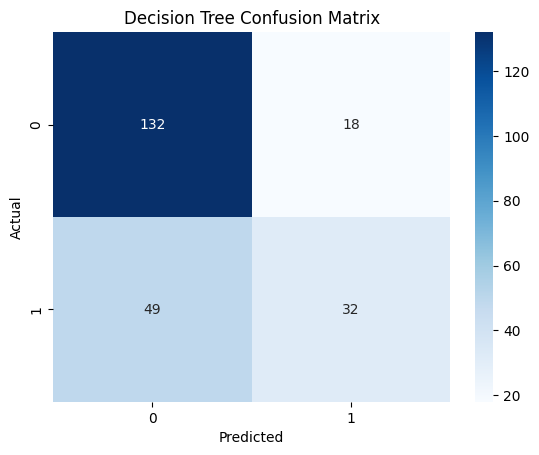

In [ ]:
print("Decision Tree Accuracy:", accuracy_score(y_test, y_pred_dt))
print("Decision Tree Precision:", precision_score(y_test, y_pred_dt))
print("Decision Tree Recall:", recall_score(y_test, y_pred_dt))
print("Decision Tree F1-Score:", f1_score(y_test, y_pred_dt))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))

sns.heatmap(
    confusion_matrix(y_test, y_pred_dt),
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

**Visualize the Decision Tree**

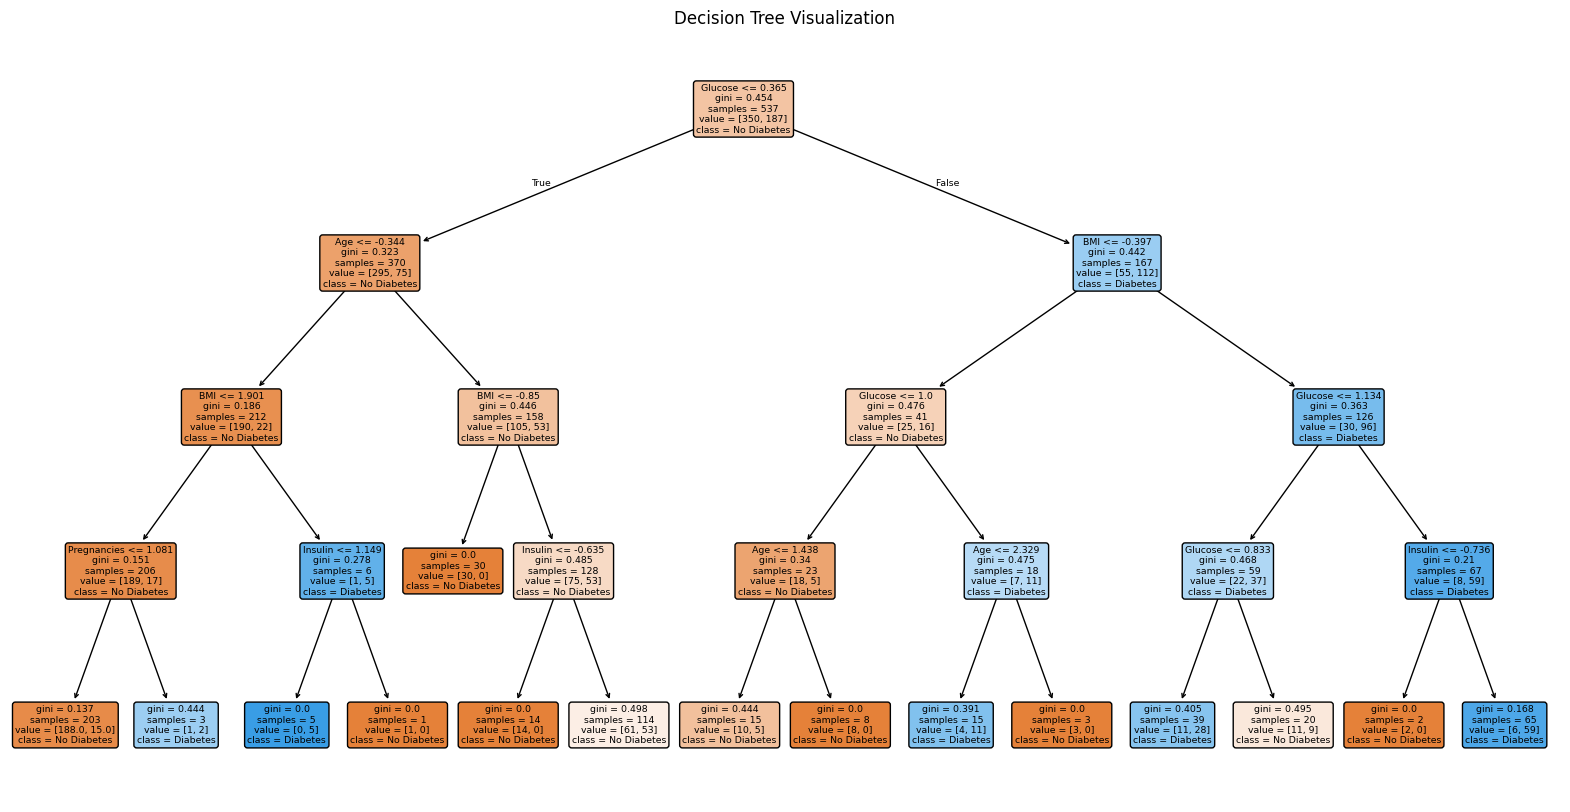

In [ ]:
plt.figure(figsize=(20, 10))

plot_tree(
    dt,
    feature_names=X.columns,
    class_names=['No Diabetes', 'Diabetes'],
    filled=True,
    rounded=True
)

plt.title("Decision Tree Visualization")
plt.show()

# **Identify the Best Model**

In [ ]:
import pandas as pd
from sklearn.metrics import accuracy_score

# Compare the 3 models
results_df = pd.DataFrame({
    'Model': ['KNN', 'SVM', 'Decision Tree'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_knn),
        accuracy_score(y_test, y_pred_svm),
        accuracy_score(y_test, y_pred_dt)
    ]
})

print("Model Comparison:")
print(results_df)

# Select the best model
best_model = results_df.loc[results_df['Accuracy'].idxmax()]

print("\nBest Model:", best_model['Model'])
print("Best Accuracy:", round(best_model['Accuracy'] * 100, 2), "%")

Model Comparison:
           Model  Accuracy
0            KNN  0.744589
1            SVM  0.744589
2  Decision Tree  0.709957

Best Model: KNN
Best Accuracy: 74.46 %


# **Conclusion**

*   Upon comparing the baseline metrics of the three models, both K-Nearest Neighbors (KNN) and Support Vector Machine (SVM) achieved the highest overall accuracy score of approximately 74.46% (0.744589).
*   The script ultimately selected KNN as the overall "Best Model" based on its leading accuracy.
*   A deeper analysis of secondary metrics supports KNN as the optimal choice for this dataset: While SVM had a slightly higher precision (68.3% compared to KNN's 65.3%), KNN achieved significantly better recall (58.0% compared to SVM's 50.6%) and a higher F1-score (61.4% compared to SVM's 58.2%).
*  This indicates that KNN is more capable of correctly identifying true positive diabetes cases (fewer false negatives) and offers a better balance between precision and recall.
*   The Decision Tree model noticeably underperformed relative to the others, scoring the lowest overall accuracy at approximately 71.00% (0.709957).
*   Furthermore, the Decision Tree struggled the most with capturing true positive cases, yielding the lowest recall (39.5%) and lowest F1-score (~48.9%) of the three evaluated classifiers.